Моделирование отклика детектора вдоль вертикальной оси...
  Z, м |  Без затухания (Q) |   С затуханием (Q)
--------------------------------------------------
  -1.5 |        7.5 ± 3.1   |        5.6 ± 2.9  
  -1.0 |       16.7 ± 5.2   |       12.9 ± 4.4  
  -0.5 |       25.9 ± 6.3   |       19.6 ± 5.4  
   0.0 |      125.7 ± 13.7  |       97.0 ± 12.2 
   0.5 |       16.7 ± 5.0   |       12.9 ± 4.3  
   1.0 |       10.3 ± 3.9   |        8.4 ± 3.7  
   1.5 |       10.8 ± 4.0   |        8.3 ± 3.7  


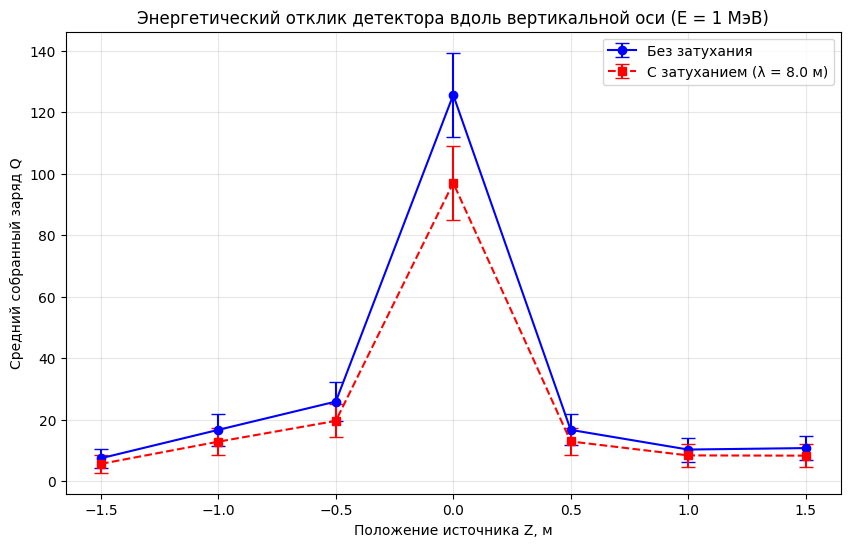

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

class Detector:
    def __init__(self, R, r, N):
        self.R = R
        self.r = r
        self.N = N
        self.positions = self._place_pmt()

    def _place_pmt(self):
        points = []
        while len(points) < self.N:
            p = np.random.uniform(-1, 1, size=3)
            length = np.linalg.norm(p)
            if 0 < length <= 1:
                points.append(p / length * self.R)
        return np.array(points)


def simulate_event(E, det, source_pos=(0.0, 0.0, 0.0), Y=10000, a=0.5, att_length=None):
    N_photons = int(E * Y)
    source_pos = np.array(source_pos)
    
    phi = np.random.uniform(0, 2 * np.pi, N_photons)
    cos_theta = np.random.uniform(-1, 1, N_photons)
    sin_theta = np.sqrt(1 - cos_theta**2)
    
    x = sin_theta * np.cos(phi)
    y = sin_theta * np.sin(phi)
    z = cos_theta
    directions = np.column_stack((x, y, z))
    
    hit_points = directions * det.R + source_pos
    
    total_electrons = 0
    
    for center in det.positions:
        vec_to_center = center - hit_points
        dist_to_center = np.linalg.norm(vec_to_center, axis=1)

        hits_mask = dist_to_center <= det.r
        num_hits = np.sum(hits_mask)
        
        if num_hits > 0:
            if att_length is not None:
                total_path_length = det.R + dist_to_center[hits_mask]
                survival_prob = np.exp(-total_path_length / att_length)
                survived = np.random.uniform(0, 1, num_hits) < survival_prob
                num_hits = np.sum(survived)
                
            if num_hits > 0:
                total_electrons += np.random.poisson(a * num_hits)
                
    return total_electrons

det = Detector(R=2.0, r=0.1, N=40)
att_length = 8.0  
E = 1.0           #в МэВ
N_events = 1000

z_positions = [-1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5]

means_no_att = []
means_att = []
stds_no_att = []
stds_att = []

print("Моделирование отклика детектора вдоль вертикальной оси...")
print(f"{'Z, м':>6} | {'Без затухания (Q)':>18} | {'С затуханием (Q)':>18}")
print("-" * 50)

for z in z_positions:
    src_pos = (0.0, 0.0, z)
    
    charges_no_att = [simulate_event(E, det, source_pos=src_pos, att_length=None) for _ in range(N_events)]
    means_no_att.append(np.mean(charges_no_att))
    stds_no_att.append(np.std(charges_no_att))
    
    charges_att = [simulate_event(E, det, source_pos=src_pos, att_length=att_length) for _ in range(N_events)]
    means_att.append(np.mean(charges_att))
    stds_att.append(np.std(charges_att))
    
    print(f"{z:>6.1f} | {means_no_att[-1]:>10.1f} ± {stds_no_att[-1]:<5.1f} | {means_att[-1]:>10.1f} ± {stds_att[-1]:<5.1f}")


plt.figure(figsize=(10, 6))

plt.errorbar(z_positions, means_no_att, yerr=stds_no_att, fmt='o-', 
             label='Без затухания', capsize=5, color='blue')
plt.errorbar(z_positions, means_att, yerr=stds_att, fmt='s--', 
             label=f'С затуханием (λ = {att_length} м)', capsize=5, color='red')

plt.xlabel('Положение источника Z, м')
plt.ylabel('Средний собранный заряд Q')
plt.title('Энергетический отклик детектора вдоль вертикальной оси (E = 1 МэВ)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
charges_center_no = [simulate_event(E, det, source_pos=(0,0,0)) for _ in range(1000)]
charges_center_att = [simulate_event(E, det, source_pos=(0,0,0), att_length=att_length) for _ in range(1000)]
plt.hist(charges_center_no, bins=30, alpha=0.5, label='Без затухания', color='blue')
plt.hist(charges_center_att, bins=30, alpha=0.5, label='С затуханием', color='red')
plt.title('Источник в центре (Z = 0 м)')
plt.xlabel('Заряд Q')
plt.ylabel('Количество событий')
plt.legend()

plt.subplot(1, 2, 2)
charges_edge_no = [simulate_event(E, det, source_pos=(0,0,1.5)) for _ in range(1000)]
charges_edge_att = [simulate_event(E, det, source_pos=(0,0,1.5), att_length=att_length) for _ in range(1000)]
plt.hist(charges_edge_no, bins=30, alpha=0.5, label='Без затухания', color='blue')
plt.hist(charges_edge_att, bins=30, alpha=0.5, label='С затуханием', color='red')
plt.title('Источник смещен вверх (Z = 1.5 м)')
plt.xlabel('Заряд Q')
plt.legend()

plt.tight_layout()
plt.show()